In [1]:
import matplotlib.pyplot as plt
import numpy as np
import cvxpy as cp

def project_onto_constraint(Y, X, beta_hat):
    # Compute the residual R = X beta_hat - Y
    R = X @ beta_hat - Y  # Dimensions: (n x m)
    
    # Compute M = X X^T
    M = X @ X.T  # Dimensions: (n x n)
    
    # Solve M Lambda = R for Lambda (n x m)
    # Use least squares in case M is singular
    Lambda, residuals, rank, s = np.linalg.lstsq(M, R, rcond=None)
    
    # Compute beta_proj = beta_hat - X^T Lambda
    beta_proj = beta_hat - X.T @ Lambda  # Dimensions: (p x m)
    
    # Compute Y_proj = X beta_proj
    Y_proj = X @ beta_proj  # Dimensions: (n x m)
    
    return beta_proj, Y_proj


def group_lasso_norm(beta):  # beta_bp
    """Computes the group basis pursuit loss of the matrix beta"""
    output = np.linalg.norm(beta, axis=1).sum()
    return output


def group_basis_pursuit(
    matrix,
    eps=1e-12,
    threshold=1e-6,
    max_iters = 2500,
    seed = 0,
    target = None,
):

    D,P = matrix.shape
    if target is None:
        target = np.identity(D)
    np.random.seed(seed)
    initialization = np.random.randn(P, D)
#     print(initialization)
#     beta = cp.Variable((P, D), value=initialization)  # Random initialization
    beta = cp.Variable((P,D))  # could initialize with lasso?
#     beta.value = np.asarray([[1.,0], [0,1.],[0,0],[0,0]])
    objective = cp.Minimize(cp.sum(cp.norm(beta, axis=1)))
    constraints = [matrix @ beta == target]
    problem = cp.Problem(objective, constraints)
    scs_opts = {"eps": eps, "max_iters": max_iters, "scale": 10.}
    output = problem.solve(solver=cp.SCS, **scs_opts)
#     output = problem.solve(solver = cp.ECOS)
    if output is np.inf:
        raise ValueError("No solution found")
    beta_optimized = beta.value
    beta_sparse = beta_optimized.copy()
    beta_sparse[np.abs(beta_sparse) < threshold] = 0
    return beta_sparse


/Users/samsonkoelle/miniconda3/envs/isometry/lib/python3.10/site-packages/cvxpy/problems/problem.py:1407: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


Angle:  0.00
  Loss improvement over naive:  0.000000
  Constraint violation:         0.000000e+00

Angle:  0.17
  Loss improvement over naive: -0.000000
  Constraint violation:         4.254652e-30

Angle:  0.35
  Loss improvement over naive: -0.000000
  Constraint violation:         3.243192e-30

Angle:  0.52
  Loss improvement over naive:  0.000000
  Constraint violation:         7.992709e-32

Angle:  0.70
  Loss improvement over naive:  0.000000
  Constraint violation:         1.735903e-31

Angle:  0.87
  Loss improvement over naive:  0.000000
  Constraint violation:         9.271158e-30

Angle:  1.05
  Loss improvement over naive:  0.000000
  Constraint violation:         5.460903e-32

Angle:  1.22
  Loss improvement over naive:  0.000000
  Constraint violation:         1.851590e-30

Angle:  1.40
  Loss improvement over naive:  0.000000
  Constraint violation:         2.415987e-31

Angle:  1.57
  Loss improvement over naive:  0.000000
  Constraint violation:         1.974259e-33



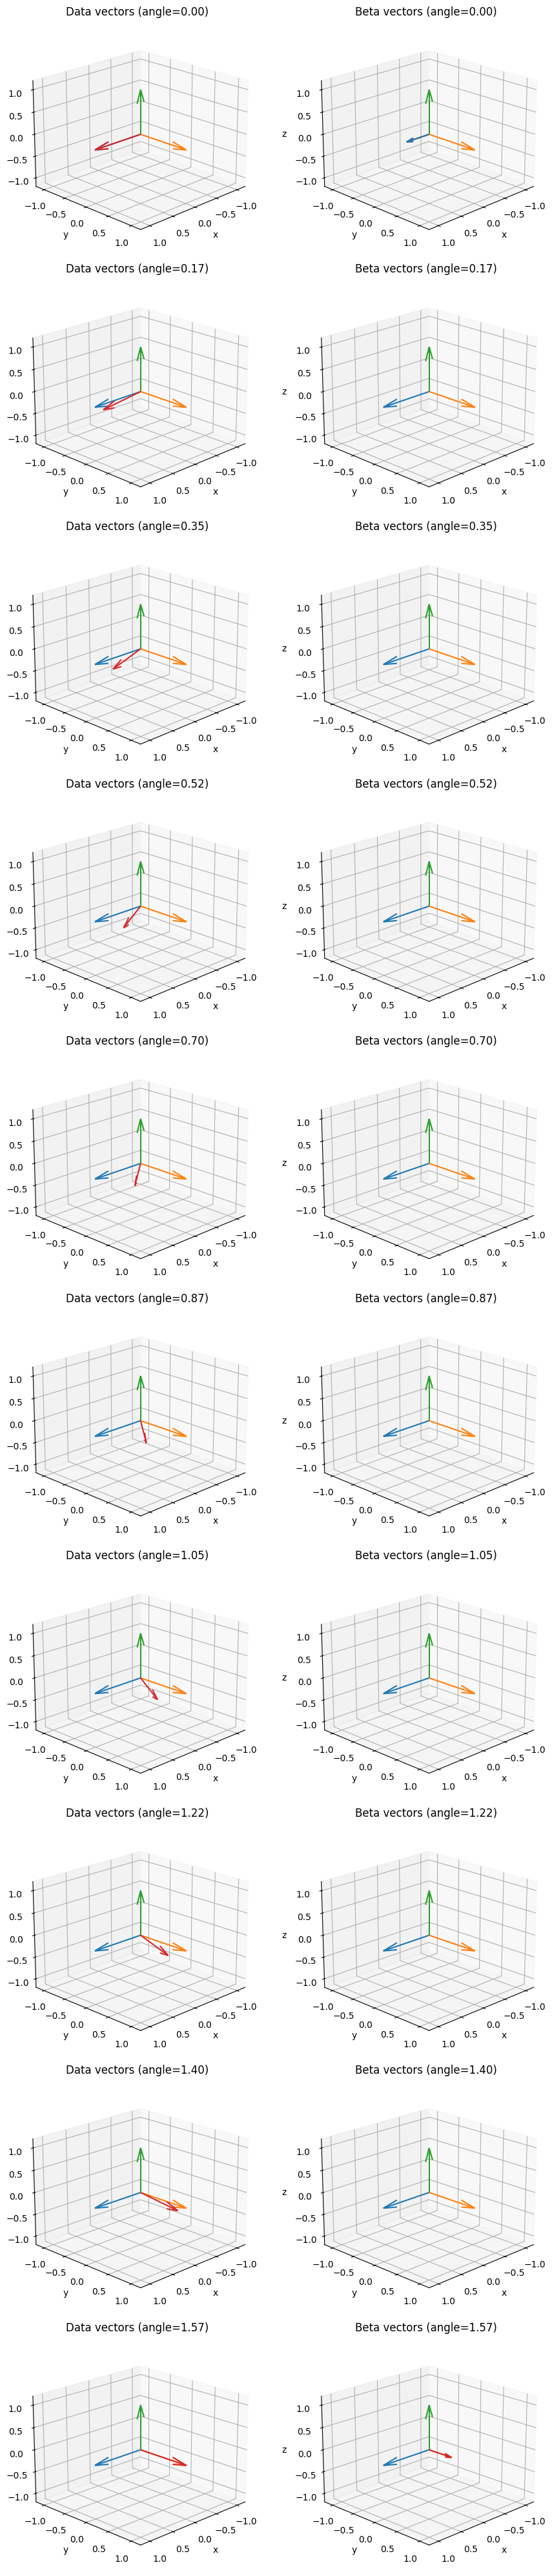

In [2]:
D = 3  # dimension of ambient space
angles = np.linspace(0, np.pi/2, 10)
betas = []
datas = []

# We will construct 4 vectors in R^3 for each angle.
# For variety, let's pivot the 4th vector with 'angle' in the xy-plane
# and let the 3rd vector tilt in the z-direction with a sine function.
# This is just an example; feel free to adjust as desired.
for i, angle in enumerate(angles):
    # Construct a (3 x 4) matrix. Each column is a 3D vector.
    data = np.array([
        [1,  0,  0],                      # e1
        [0,  1,  0],                      # e2
        [0,  0,  1],                      # e3
        [np.cos(angle), np.sin(angle), 0] # rotating in xy-plane
    ]).T  # shape = (3,4)

    datas.append(data)

    # Solve group basis pursuit:  data @ beta = I_3
    beta_putative = group_basis_pursuit(
        data, 
        eps=1e-14, 
        max_iters=50000, 
        seed=i * 5, 
        target=np.eye(D)
    )
    
    # Project onto the constraint for numeric consistency
    beta, _ = project_onto_constraint(np.eye(D), data, beta_putative)

    betas.append(beta)

    # Just a quick console check
    improvement = (D - group_lasso_norm(beta))  # difference from naive norm = D if beta was identity
    constraint_violation = np.linalg.norm(np.eye(D) - data @ beta)
    print(f"Angle: {angle: .2f}")
    print(f"  Loss improvement over naive: {improvement: .6f}")
    print(f"  Constraint violation:        {constraint_violation: .6e}\n")


# ---------------------------------------------------------
# Plotting in 3D
# We'll make 10 rows x 2 columns of subplots in 3D
# Left column: the data vectors
# Right column: the solution beta vectors
# ---------------------------------------------------------
fig = plt.figure(figsize=(10, 40))

for i, (data, beta) in enumerate(zip(datas, betas)):
    # ============== Plot data ==============
    ax_data = fig.add_subplot(10, 2, 2*i + 1, projection='3d')
    ax_data.set_title(f"Data vectors (angle={angles[i]:.2f})")
    
    # Each column of data is a 3D vector
    for col_idx in range(data.shape[1]):
        v = data[:, col_idx]
        ax_data.quiver(0, 0, 0, v[0], v[1], v[2], 
                       length=1.0, normalize=False,
                       color=plt.cm.tab10(col_idx))
    
    # Set axes limits & labels
    ax_data.set_xlim([-1.2, 1.2])
    ax_data.set_ylim([-1.2, 1.2])
    ax_data.set_zlim([-1.2, 1.2])
    ax_data.set_xlabel('x')
    ax_data.set_ylabel('y')
    ax_data.set_zlabel('z')
    ax_data.view_init(elev=20, azim=45)  # tilt the 3D view

    # ============== Plot beta ==============
    ax_beta = fig.add_subplot(10, 2, 2*i + 2, projection='3d')
    ax_beta.set_title(f"Beta vectors (angle={angles[i]:.2f})")
    
    for row_idx in range(beta.shape[0]):
        # Each row in 'beta' is a 3D vector (in practice, shape=(P,3))
        v = beta[row_idx, :]  # shape (3,)
        ax_beta.quiver(0, 0, 0, v[0], v[1], v[2],
                       length=1.0, normalize=False,
                       color=plt.cm.tab10(row_idx))

    ax_beta.set_xlim([-1.2, 1.2])
    ax_beta.set_ylim([-1.2, 1.2])
    ax_beta.set_zlim([-1.2, 1.2])
    ax_beta.set_xlabel('x')
    ax_beta.set_ylabel('y')
    ax_beta.set_zlabel('z')
    ax_beta.view_init(elev=20, azim=45)

plt.tight_layout()
plt.show()

Loss improvement relative to naive: 0.0
Constraint violation: 6.60516211885202e-17


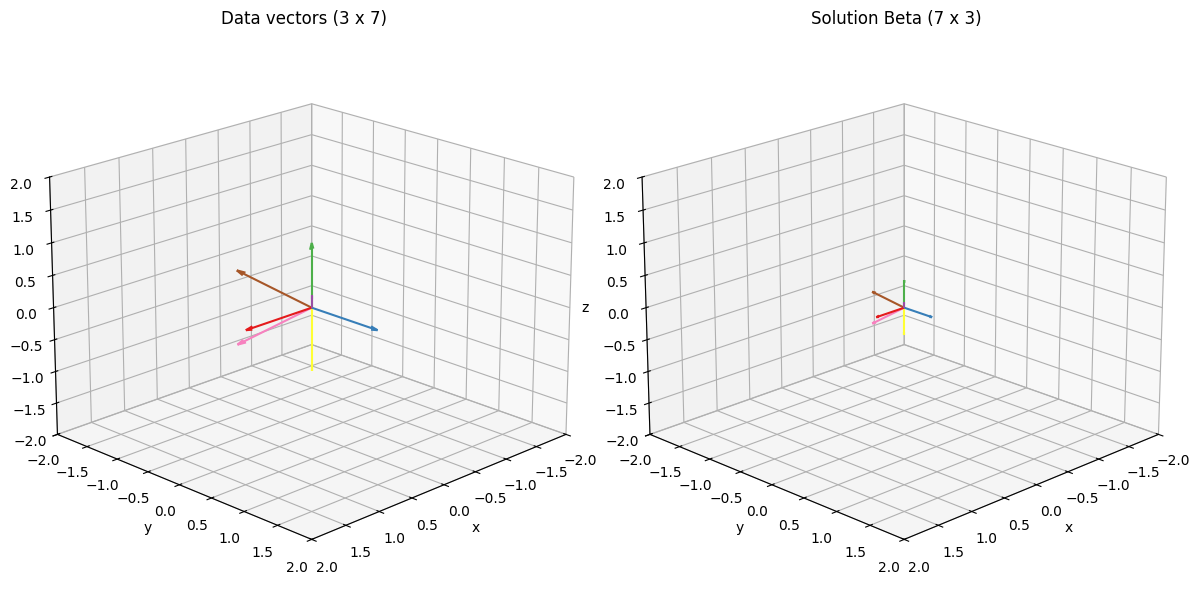

In [13]:

# --------------------------------------------------------------------------
# 2) Construct the Data Matrix (3 x 7)
#    * standard basis e1, e2, e3
#    * 4 non-identity vectors in different orthants, x>0
# --------------------------------------------------------------------------
data = np.array([
    [1,  0,  0],   # e1
    [0,  1,  0],   # e2
    [0,  0,  1],   # e3

    # 4 vectors with x>0, covering different signs of (y,z)
    [1,  1,  1],   # x>0, y>0, z>0
    [1,  1, -1],   # x>0, y>0, z<0
    [1, -1,  1],   # x>0, y<0, z>0
    [1, -1, -1],   # x>0, y<0, z<0
]).T  # shape becomes (3, 7)

data = data / np.linalg.norm(data, axis = 0)
# --------------------------------------------------------------------------
# 3) Solve Group Basis Pursuit:  data @ beta = I_3
# --------------------------------------------------------------------------
beta_init = group_basis_pursuit(
    matrix=data, 
    eps=1e-14,
    max_iters=30000,
    seed=42,
    target=np.eye(3)
)

# For numerical stability, project solution onto constraint
beta_proj, _ = project_onto_constraint(np.eye(3), data, beta_init)

# Evaluate how "sparse" (group-lasso sense) and the constraint violation
loss_improvement = 3 - group_lasso_norm(beta_proj)  # naive "row-norm-sum" would be 3 if identity
constraint_error = np.linalg.norm(np.eye(3) - data @ beta_proj)
print("Loss improvement relative to naive:", loss_improvement)
print("Constraint violation:", constraint_error)


# --------------------------------------------------------------------------
# 4) Plot the Data (left) and the Solution Beta (right) in 3D
# --------------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))

# -- Left: The 7 data vectors in 3D --
ax_data = fig.add_subplot(1, 2, 1, projection='3d')
ax_data.set_title("Data vectors (3 x 7)")
for col_idx in range(data.shape[1]):
    v = data[:, col_idx]  # shape (3,)
    ax_data.quiver(
        0, 0, 0,          # start
        v[0], v[1], v[2], # direction
        length=1.0,
        normalize=False,
        arrow_length_ratio=0.1,
        color=plt.cm.Set1(col_idx / data.shape[1])
    )
ax_data.set_xlim([-2, 2])
ax_data.set_ylim([-2, 2])
ax_data.set_zlim([-2, 2])
ax_data.set_xlabel("x")
ax_data.set_ylabel("y")
ax_data.set_zlabel("z")
ax_data.view_init(elev=20, azim=45)

# -- Right: The 7 rows of Beta in 3D --
ax_beta = fig.add_subplot(1, 2, 2, projection='3d')
ax_beta.set_title("Solution Beta (7 x 3)")
for row_idx in range(beta_proj.shape[0]):
    v = beta_proj[row_idx, :]  # shape (3,)
    ax_beta.quiver(
        0, 0, 0,
        v[0], v[1], v[2],
        length=1.0,
        normalize=False,
        arrow_length_ratio=0.1,
        color=plt.cm.Set1(row_idx / beta_proj.shape[0])
    )
ax_beta.set_xlim([-2, 2])
ax_beta.set_ylim([-2, 2])
ax_beta.set_zlim([-2, 2])
ax_beta.set_xlabel("x")
ax_beta.set_ylabel("y")
ax_beta.set_zlabel("z")
ax_beta.view_init(elev=20, azim=45)

plt.tight_layout()
plt.show()

array([[ 1.        ,  0.        ,  0.        ,  0.57735027,  0.57735027,
         0.57735027,  0.57735027],
       [ 0.        ,  1.        ,  0.        ,  0.57735027,  0.57735027,
        -0.57735027, -0.57735027],
       [ 0.        ,  0.        ,  1.        ,  0.57735027, -0.57735027,
         0.57735027, -0.57735027]])